# Visualizaciones (Punto 13)
Gráficos del conjunto de datos resultante de los ítems 4 a 6: la variable `IMC` (punto 4), el merge con las regiones (punto 5) y la variable `medalla` (punto 6). Cada gráfico se guarda en PNG en `outputs/graficos/`.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_atletas = pd.read_csv('../data/athlete_events.csv')
df_regiones = pd.read_csv('../data/noc_regions.csv')

df_atletas['IMC'] = df_atletas['Weight'] / ((df_atletas['Height'] / 100) ** 2)
df_atletas = pd.merge(df_atletas, df_regiones, on='NOC', how='left')
df_atletas['medalla'] = df_atletas['Medal'].notna().astype(int)

os.makedirs('../outputs/graficos', exist_ok=True)
plt.rcParams['figure.dpi'] = 110

### Gráfico 1. Distribución del IMC (punto 4)

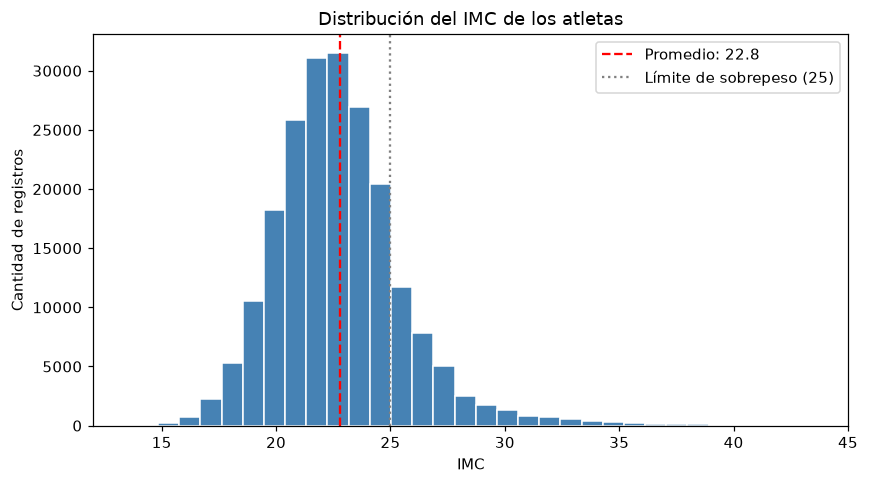

Promedio: 22.78  Mediana: 22.53
% de registros con IMC mayor a 25: 16.42


In [2]:
imc = df_atletas['IMC'].dropna()

plt.figure(figsize=(8, 4.5))
plt.hist(imc, bins=60, color='steelblue', edgecolor='white')
plt.axvline(imc.mean(), color='red', linestyle='--', label=f'Promedio: {imc.mean():.1f}')
plt.axvline(25, color='gray', linestyle=':', label='Límite de sobrepeso (25)')
plt.title('Distribución del IMC de los atletas')
plt.xlabel('IMC')
plt.ylabel('Cantidad de registros')
plt.xlim(12, 45)
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/graficos/01_distribucion_imc.png')
plt.show()

print("Promedio:", round(imc.mean(), 2), " Mediana:", round(imc.median(), 2))
print("% de registros con IMC mayor a 25:", round((imc > 25).mean() * 100, 2))

**Interpretación:** la mayoría de los atletas tiene un IMC concentrado alrededor del promedio que aparece en la línea roja, dentro del rango considerado normal. Hay una cola hacia la derecha con valores altos, que corresponde a atletas muy pesados. Como se discutió en el punto 4, esos valores altos no significan sobrepeso, sino mucha masa muscular en ciertos deportes.

### Gráfico 2. IMC según el deporte (punto 4)

/tmp/ipykernel_11918/1524904788.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot([datos[i] for i in orden], vert=False, showfliers=False)


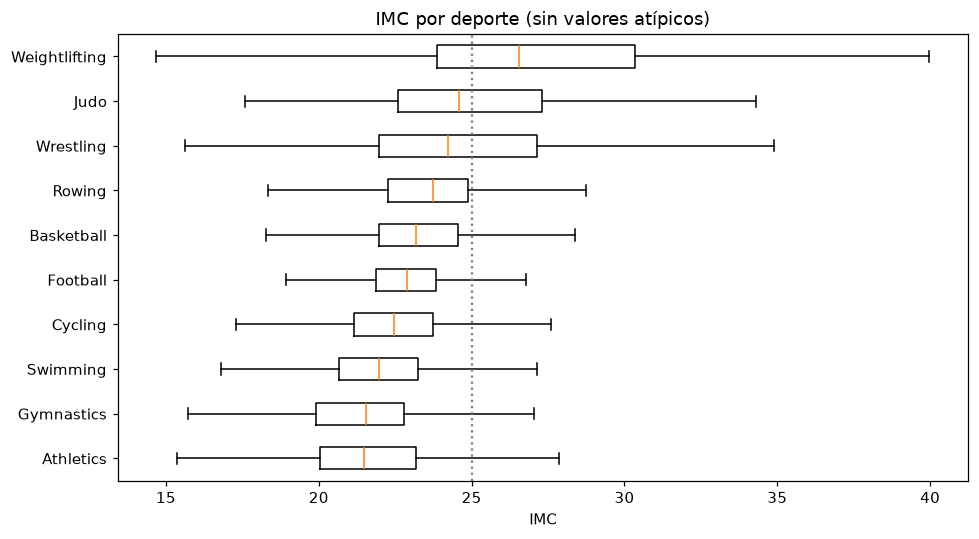

Sport
Athletics        21.47
Gymnastics       21.55
Swimming         21.97
Cycling          22.47
Football         22.88
Basketball       23.17
Rowing           23.74
Wrestling        24.22
Judo             24.59
Weightlifting    26.53
Name: IMC, dtype: float64


In [3]:
deportes = ['Weightlifting', 'Wrestling', 'Judo', 'Athletics', 'Swimming',
            'Basketball', 'Football', 'Cycling', 'Rowing', 'Gymnastics']
datos = [df_atletas.loc[df_atletas['Sport'] == d, 'IMC'].dropna() for d in deportes]
orden = np.argsort([d.median() for d in datos])

plt.figure(figsize=(9, 5))
plt.boxplot([datos[i] for i in orden], vert=False, showfliers=False)
plt.yticks(range(1, len(deportes) + 1), [deportes[i] for i in orden])
plt.axvline(25, color='gray', linestyle=':')
plt.title('IMC por deporte (sin valores atípicos)')
plt.xlabel('IMC')
plt.tight_layout()
plt.savefig('../outputs/graficos/02_imc_por_deporte.png')
plt.show()

print(df_atletas[df_atletas['Sport'].isin(deportes)].groupby('Sport')['IMC'].median().round(2).sort_values())

    **Interpretación:** el IMC cambia mucho según el deporte. Los deportes de fuerza y contacto, como halterofilia, lucha y judo, tienen las medianas más altas y varios atletas por encima de 25. En cambio, atletismo, gimnasia y natación tienen valores más bajos, porque ahí un cuerpo liviano es una ventaja. Esto confirma lo del punto 4: el IMC solo tiene sentido si se compara dentro del mismo deporte.

### Gráfico 3. Regiones con más participaciones (punto 5)

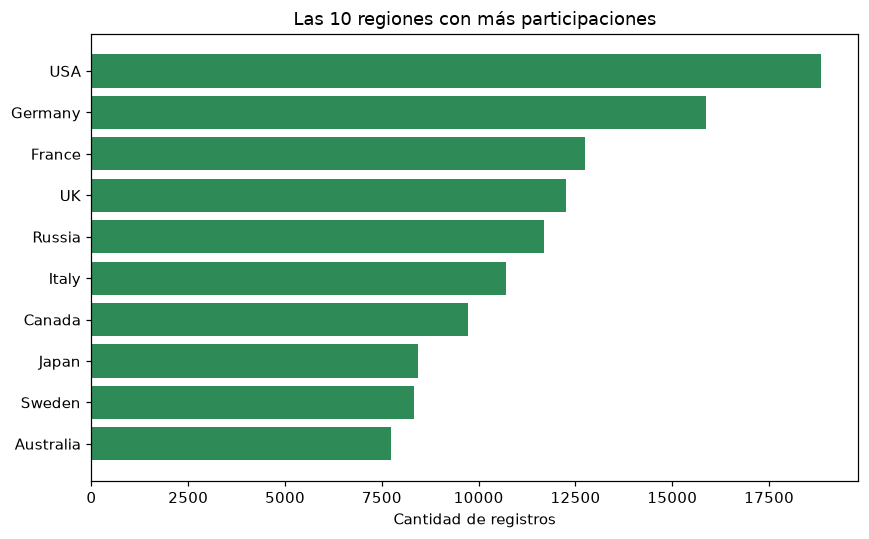

Registros sin región: 370


In [4]:
top_regiones = df_atletas['region'].value_counts().head(10).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(top_regiones.index, top_regiones.values, color='seagreen')
plt.title('Las 10 regiones con más participaciones')
plt.xlabel('Cantidad de registros')
plt.tight_layout()
plt.savefig('../outputs/graficos/03_top_regiones.png')
plt.show()

print("Registros sin región:", df_atletas['region'].isna().sum())

**Interpretación:** gracias al merge con `noc_regions.csv` ahora cada registro tiene un país. Las regiones con más participaciones son potencias deportivas con delegaciones grandes y que han ido a casi todas las ediciones. Además, el merge agrupa códigos históricos en un solo país (por ejemplo, las dos Alemanias quedan como Germany), por eso algunos países suman tantos registros. Solo 370 registros quedaron sin región, que es muy poco frente al total.

### Gráfico 4. Registros con y sin medalla (punto 6)

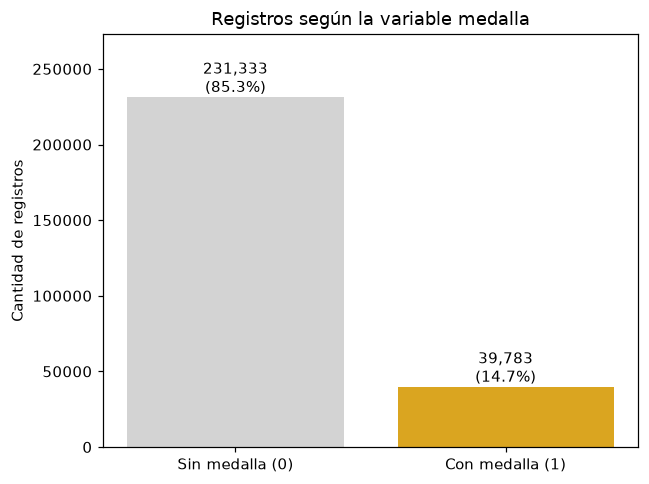

In [5]:
conteo = df_atletas['medalla'].value_counts().sort_index()

plt.figure(figsize=(6, 4.5))
barras = plt.bar(['Sin medalla (0)', 'Con medalla (1)'], conteo.values, color=['lightgray', 'goldenrod'])
for b, v in zip(barras, conteo.values):
    plt.text(b.get_x() + b.get_width() / 2, v, f'{v:,}\n({v / conteo.sum() * 100:.1f}%)', ha='center', va='bottom')
plt.title('Registros según la variable medalla')
plt.ylabel('Cantidad de registros')
plt.ylim(0, conteo.max() * 1.18)
plt.tight_layout()
plt.savefig('../outputs/graficos/04_distribucion_medalla.png')
plt.show()

**Interpretación:** la variable `medalla` está muy desbalanceada: la gran mayoría de las participaciones no termina en medalla y solo cerca del 15% sí. Por eso, al comparar grupos, conviene usar tasas (porcentaje de medallas sobre participaciones) y no solo conteos, como se hizo en el punto 10.

### Gráfico 5. Tasa de medalla por región (puntos 5 y 6)

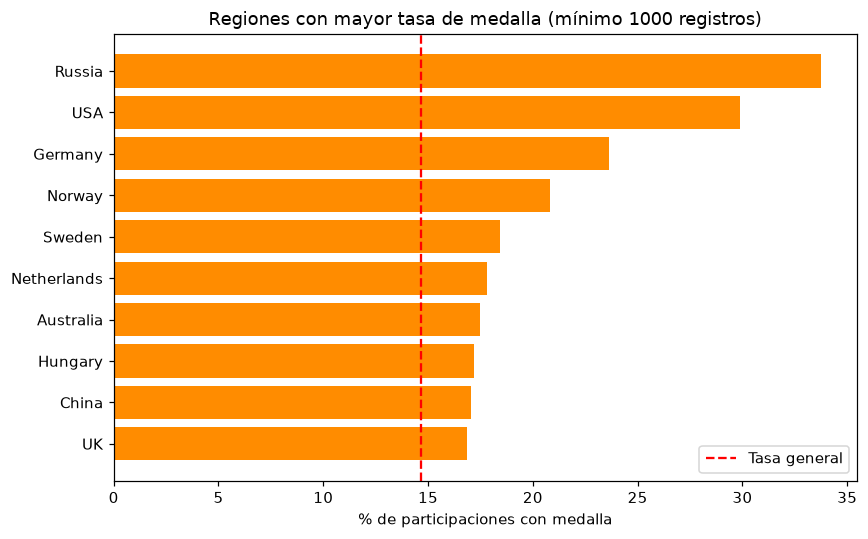

region
Russia         33.76
USA            29.90
Germany        23.65
Norway         20.83
Sweden         18.42
Netherlands    17.81
Australia      17.47
Hungary        17.18
China          17.04
UK             16.87
Name: mean, dtype: float64


In [6]:
por_region = df_atletas.groupby('region')['medalla'].agg(['mean', 'count'])
por_region = por_region[por_region['count'] >= 1000]
top_tasa = (por_region['mean'] * 100).sort_values(ascending=False).head(10).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(top_tasa.index, top_tasa.values, color='darkorange')
plt.axvline(df_atletas['medalla'].mean() * 100, color='red', linestyle='--', label='Tasa general')
plt.title('Regiones con mayor tasa de medalla (mínimo 1000 registros)')
plt.xlabel('% de participaciones con medalla')
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/graficos/05_tasa_medalla_por_region.png')
plt.show()

print(top_tasa.round(2).sort_values(ascending=False))

**Interpretación:** este gráfico une el merge del punto 5 con la variable `medalla` del punto 6. Se filtraron las regiones con al menos 1000 registros para no exagerar países con muy pocos atletas. Las regiones con mayor tasa están muy por encima de la tasa general (línea roja), lo que muestra que la probabilidad de ganar medalla depende mucho del país que representa el atleta.

### Gráfico 6. IMC de atletas con y sin medalla (puntos 4 y 6)

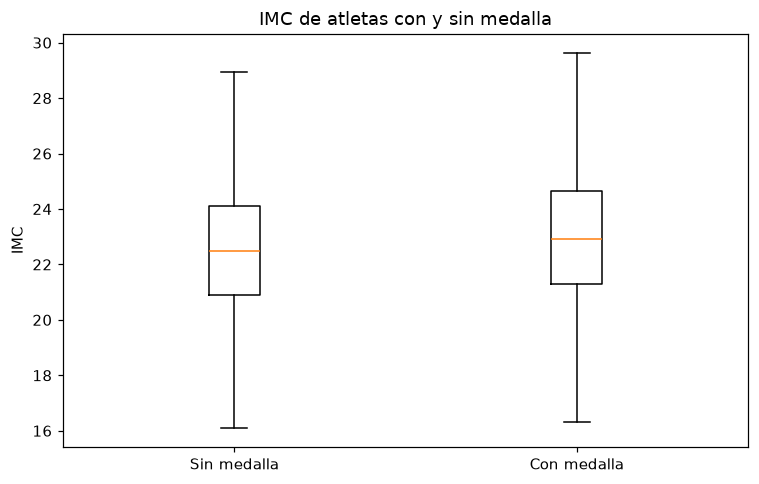

Mediana IMC sin medalla: 22.48
Mediana IMC con medalla: 22.93


In [7]:
sin_med = df_atletas.loc[df_atletas['medalla'] == 0, 'IMC'].dropna()
con_med = df_atletas.loc[df_atletas['medalla'] == 1, 'IMC'].dropna()

plt.figure(figsize=(7, 4.5))
plt.boxplot([sin_med, con_med], showfliers=False)
plt.xticks([1, 2], ['Sin medalla', 'Con medalla'])
plt.title('IMC de atletas con y sin medalla')
plt.ylabel('IMC')
plt.tight_layout()
plt.savefig('../outputs/graficos/06_imc_vs_medalla.png')
plt.show()

print("Mediana IMC sin medalla:", round(sin_med.median(), 2))
print("Mediana IMC con medalla:", round(con_med.median(), 2))

**Interpretación:** las cajas de los atletas con y sin medalla son muy parecidas, o sea que el IMC por sí solo no explica quién gana. Esto tiene sentido, porque cada deporte pide un tipo de cuerpo distinto (gráfico 2), entonces al mezclar todos los deportes el efecto del IMC se pierde.